# Photoreal real2sim: splats composited into LIBERO

Gaussian splats replace the *appearance* of chosen LIBERO bodies (table, bowl, plate); physics and the robot stay LIBERO's own. The robot mesh and the splats are merged per pixel by depth.

- **Modules:** `hurobo.splat` (`SplatCompositor`, `SplatAsset`, `SplatFit`), `hurobo.sim.LiberoTask`
- **Script version:** `scripts/08_splat_composite.py` (full scripted pick-and-place video)
- **Needs:** a CUDA GPU (gsplat) and EGL; first run may JIT-compile gsplat kernels

The splats here are DISCOVERSE stand-ins, not a scan of our own table, and the motion below is only a teleported bowl, so this shows the *rendering path*, not a policy result.

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

In [9]:
%%capture
# (capture hides robosuite's startup logging)
from hurobo.sim import LiberoTask
from hurobo.splat import LIBERO_GOAL_DISTRACTOR_ROOTS, SplatCompositor, build_assets
from hurobo.utils.plotting import plot_image_row

task = LiberoTask("libero_goal", 8)
task.reset()
# build_assets: DISCOVERSE pink bowl, white plate and table cloth (downloaded on first use).
compositor = SplatCompositor(
    task.mj_model,
    build_assets(bowl_ply="data/splats/dummy_discoverse/object__bowl_pink.ply"), # object__bowl_pink.ply | dummy_fruit_bowl.ply | bowl.ply
    hidden_body_roots=LIBERO_GOAL_DISTRACTOR_ROOTS,
    width=384,
    height=384,
)

In [6]:
print(f"{compositor.num_gaussians:,} Gaussians attached")

234,481 Gaussians attached


## The four layers
Native LIBERO, the mesh layer (robot and anything not replaced), the splat layer alone, and the depth composite a policy would see.

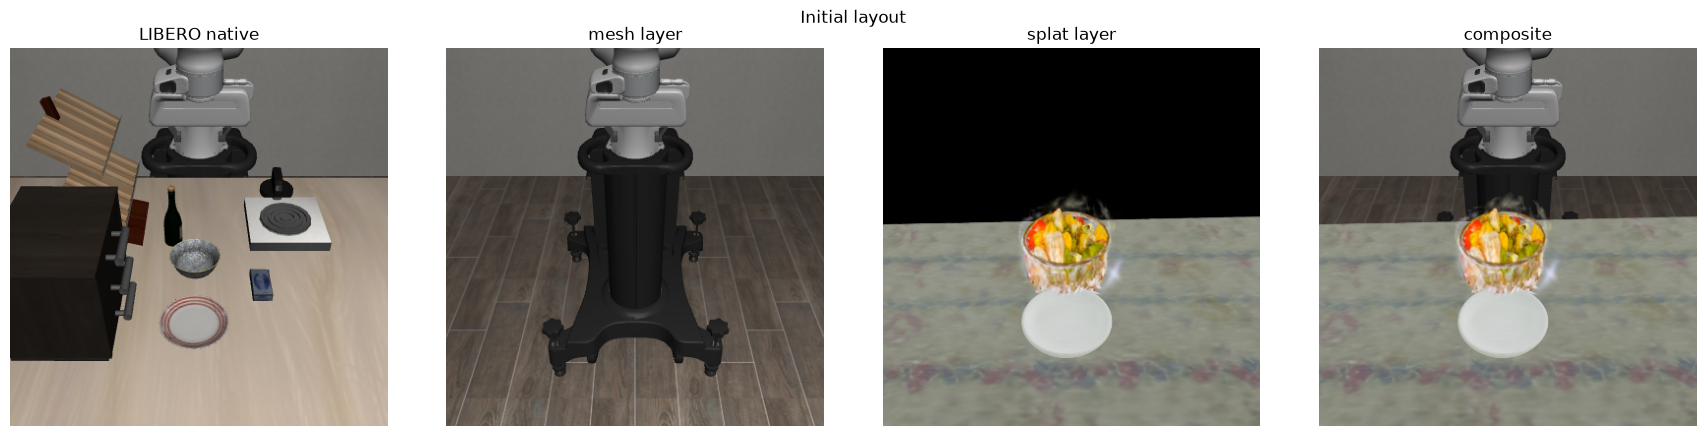

In [7]:
plot_image_row(compositor.render_layers(task.mj_data, "agentview"), "Initial layout")

## Splats follow their bodies
Move the bowl in the simulator; its splat moves with it because it is attached to the body's `xpos`/`xquat` every frame.

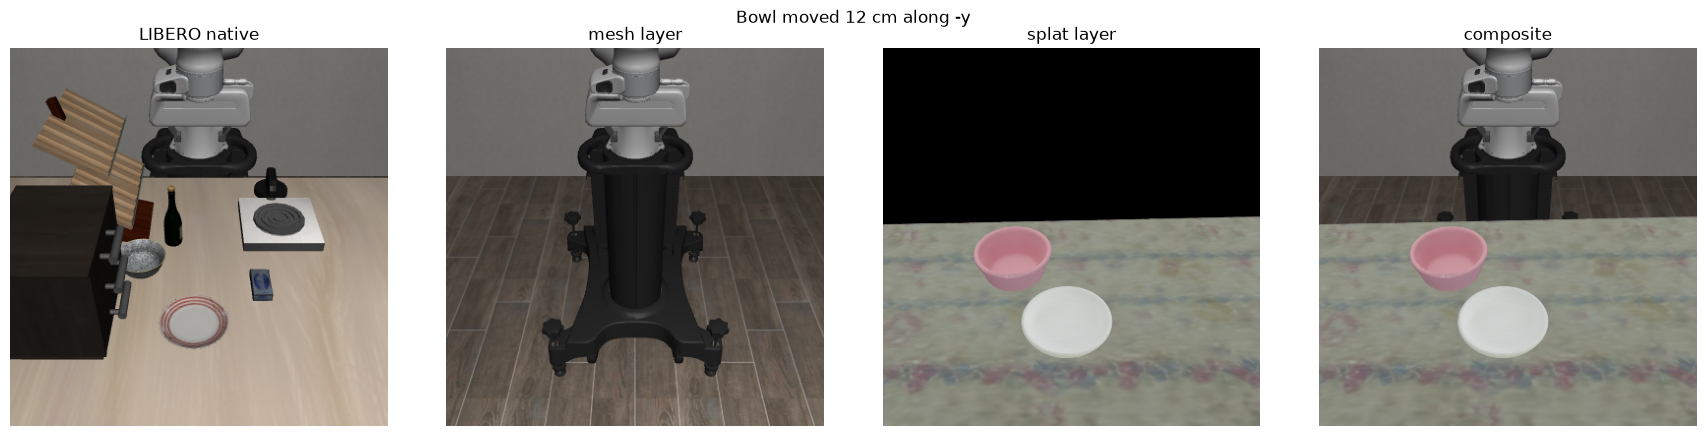

In [5]:
import numpy as np

task.translate_object("akita_black_bowl_1_joint0", np.array([0.0, -0.12, 0.0]))
plot_image_row(compositor.render_layers(task.mj_data, "agentview"), "Bowl moved 12 cm along -y")

In [6]:
compositor.close()
task.close()